In [1]:
#CELDA 1
%pip install -q kagglehub pandas numpy scikit-learn matplotlib seaborn mlflow joblib pyarrow
%pip install -q skops

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 40.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 49.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 44.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1

In [2]:
#CELDA 2
from pathlib import Path

BASE = Path("/content/Actividad5")

carpetas = [
    "datos/datos_ini",
    "datos/datos_limp",
    "fuentes",
    "evidencias/mlflow",
    "evidencias/graficas",
    "reportes",
]

for carpeta in carpetas:
    (BASE / carpeta).mkdir(parents=True, exist_ok=True)

print("Estructura creada en:", BASE)

for ruta in sorted(BASE.rglob("*")):
    print(ruta.relative_to(BASE))

Estructura creada en: /content/Actividad5
datos
datos/datos_ini
datos/datos_limp
evidencias
evidencias/graficas
evidencias/mlflow
fuentes
reportes


In [3]:
#CELDA 3
import kagglehub
import shutil

dataset_path = kagglehub.dataset_download(
    "devanshk09/complete-hyrox-dataset-with-splits-20172026"
)

origen = Path(dataset_path)
destino = BASE / "datos" / "datos_ini"

for archivo in origen.rglob("*"):
    if archivo.is_file():
        destino_archivo = destino / archivo.relative_to(origen)
        destino_archivo.parent.mkdir(parents=True, exist_ok=True)

        if not destino_archivo.exists():
            shutil.copy2(archivo, destino_archivo)

print("Descarga localizada en:", origen)
print("Archivos originales copiados en:", destino)

Using Colab cache for faster access to the 'complete-hyrox-dataset-with-splits-20172026' dataset.
Descarga localizada en: /kaggle/input/complete-hyrox-dataset-with-splits-20172026
Archivos originales copiados en: /content/Actividad5/datos/datos_ini


In [4]:
#CELDA 4
import pandas as pd

DATOS_INI = BASE / "datos" / "datos_ini"

prioridad = [
    "hyrox_full.parquet",
    "hyrox_results.parquet",
    "hyrox_clean.parquet",
    "hyrox_full.csv",
    "hyrox_results.csv",
]

archivos = {
    p.name: p
    for p in DATOS_INI.rglob("*")
    if p.is_file() and p.suffix.lower() in [".csv", ".parquet"]
}

print("Archivos consolidados encontrados:")
for nombre in prioridad:
    if nombre in archivos:
        print(nombre)

archivo = next(
    (archivos[n] for n in prioridad if n in archivos),
    None
)

if archivo is None:
    raise FileNotFoundError(
        "No se encontró un archivo consolidado conocido. "
        "Revisa la lista de archivos descargados."
    )

if archivo.suffix.lower() == ".parquet":
    df_original = pd.read_parquet(archivo)
else:
    df_original = pd.read_csv(archivo, low_memory=False)

df_original.columns = df_original.columns.astype(str).str.strip()

print("\nArchivo seleccionado:", archivo.name)
print("Dimensiones:", df_original.shape)
print("Columnas:", df_original.columns.tolist())

display(df_original.head())
display(df_original.dtypes.to_frame("tipo_dato"))

Archivos consolidados encontrados:
hyrox_full.parquet
hyrox_results.parquet
hyrox_clean.parquet
hyrox_full.csv
hyrox_results.csv

Archivo seleccionado: hyrox_full.parquet
Dimensiones: (1478643, 69)
Columnas: ['season', 'year', 'city', 'division', 'event_id', 'sex', 'idp', 'name', 'nationality', 'age_group', 'rank_overall', 'rank_age_group', 'finish_time', 'overall_time', 'rank_overall_detail', 'run_1_time', 'run_2_time', 'run_3_time', 'run_4_time', 'run_5_time', 'run_6_time', 'run_7_time', 'run_8_time', 'run_total_time', 'best_run_lap_time', 'ski_erg_time', 'ski_erg_place', 'sled_push_time', 'sled_push_place', 'sled_pull_time', 'sled_pull_place', 'burpee_broad_jump_time', 'burpee_broad_jump_place', 'row_time', 'row_place', 'farmers_carry_time', 'farmers_carry_place', 'sandbag_lunges_time', 'wall_balls_time', 'wall_balls_place', 'granular_timing_json', 'sandbag_lunges_place', 'run_total_place', 'best_run_lap_place', 'run_6_place', 'run_7_place', 'roxzone_time', 'roxzone_place', 'finish_

,season,year,city,division,event_id,sex,idp,name,nationality,age_group,...,best_run_lap_seconds,ski_erg_seconds,sled_push_seconds,sled_pull_seconds,burpee_broad_jump_seconds,row_seconds,farmers_carry_seconds,sandbag_lunges_seconds,wall_balls_seconds,roxzone_seconds
0,1,2018,Essen,HYROX DOUBLES,HD_999999212F07B5000000003D,M,999999212F07B50000005C81,Trave Crossfit,None,16-29,...,269.0,197.0,68.0,148.0,120.0,223.0,89.0,129.0,212.0,NaN
1,1,2018,Essen,HYROX DOUBLES,HD_999999212F07B5000000003D,M,999999212F07B500000054E0,Ente Süßsauer,None,16-29,...,279.0,199.0,78.0,155.0,135.0,237.0,108.0,139.0,205.0,NaN
2,1,2018,Essen,HYROX DOUBLES,HD_999999212F07B5000000003D,M,999999212F07B50000004E71,Beastmode,None,40-49,...,266.0,219.0,80.0,186.0,158.0,265.0,120.0,177.0,229.0,NaN
3,1,2018,Essen,HYROX DOUBLES,HD_999999212F07B5000000003D,M,999999212F07B50000003604,Sancho und Pancho,None,30-39,...,NaN,198.0,71.0,159.0,133.0,234.0,77.0,118.0,229.0,NaN
4,1,2018,Essen,HYROX DOUBLES,HD_999999212F07B5000000003D,M,999999212F07B500000034BD,The Old Man CF Team Delta,None,30-39,...,281.0,199.0,67.0,164.0,166.0,240.0,91.0,165.0,211.0,NaN


,tipo_dato
season,object
year,object
city,object
division,object
event_id,object
...,...
row_seconds,float64
farmers_carry_seconds,float64
sandbag_lunges_seconds,float64
wall_balls_seconds,float64


In [5]:
#CELDA 5
print("Duplicados exactos:", df_original.duplicated().sum())

calidad = pd.DataFrame({
    "tipo_dato": df_original.dtypes.astype(str),
    "nulos": df_original.isna().sum(),
    "porcentaje_nulos": (
        df_original.isna().mean() * 100
    ).round(2),
    "valores_unicos": df_original.nunique(dropna=True),
})

display(
    calidad.sort_values(
        "porcentaje_nulos",
        ascending=False
    )
)

print("Filas:", len(df_original))
print("Columnas:", len(df_original.columns))

Duplicados exactos: 0


,tipo_dato,nulos,porcentaje_nulos,valores_unicos
run_7_place,object,1478496,99.99,2
run_6_place,object,1478496,99.99,2
nationality,object,649807,43.95,235
roxzone_place,object,575597,38.93,2817
best_run_lap_place,object,551977,37.33,2808
...,...,...,...,...
finish_time,object,0,0.00,11698
name,object,0,0.00,822031
rank_overall,object,0,0.00,5714
idp,object,0,0.00,1024039


Filas: 1478643
Columnas: 69


In [6]:
#CELDA 6
import hashlib
import json

DATOS_LIMP = BASE / "datos" / "datos_limp"

sha256 = hashlib.sha256()
with open(archivo, "rb") as f:
    for bloque in iter(lambda: f.read(1024 * 1024), b""):
        sha256.update(bloque)

hash_original = sha256.hexdigest()

limpio = df_original.copy()
filas_iniciales = len(limpio)

limpio = limpio.drop_duplicates().copy()
duplicados_eliminados = filas_iniciales - len(limpio)

if "finish_seconds" not in limpio.columns:
    raise ValueError(
        "No existe finish_seconds. Revisa el diccionario "
        "de datos y la columna objetivo."
    )

limpio["finish_seconds"] = pd.to_numeric(
    limpio["finish_seconds"],
    errors="coerce"
)

objetivos_invalidos = (
    limpio["finish_seconds"].isna()
    | (limpio["finish_seconds"] <= 0)
)

filas_objetivo_invalido = int(objetivos_invalidos.sum())

limpio = limpio.loc[~objetivos_invalidos].copy()

print("Hash SHA-256 original:", hash_original)
print("Duplicados eliminados:", duplicados_eliminados)
print("Objetivos inválidos eliminados:", filas_objetivo_invalido)
print("Filas finales:", len(limpio))

# Diccionario de datos automático
diccionario = pd.DataFrame({
    "columna": limpio.columns,
    "tipo_dato": [str(limpio[c].dtype) for c in limpio.columns],
    "nulos": [int(limpio[c].isna().sum()) for c in limpio.columns],
    "porcentaje_nulos": [
        round(limpio[c].isna().mean() * 100, 2)
        for c in limpio.columns
    ],
    "valores_unicos": [
        int(limpio[c].nunique(dropna=True))
        for c in limpio.columns
    ],
})

limpio.to_parquet(
    DATOS_LIMP / "hyrox_clean.parquet",
    index=False
)

diccionario.to_csv(
    DATOS_LIMP / "diccionario_datos.csv",
    index=False,
    encoding="utf-8"
)

with open(DATOS_LIMP / "metadatos.json", "w", encoding="utf-8") as f:
    json.dump({
        "archivo_origen": archivo.name,
        "sha256_original": hash_original,
        "filas_originales": int(filas_iniciales),
        "duplicados_eliminados": int(duplicados_eliminados),
        "objetivos_invalidos_eliminados": int(filas_objetivo_invalido),
        "filas_limpias": int(len(limpio)),
        "semilla": 42,
    }, f, indent=2, ensure_ascii=False)

display(diccionario)
print("Datos limpios y diccionario guardados.")

Hash SHA-256 original: c692ccbd73169b19ce9c423234f22bb29c09f3c1eff1d8861b1789f1b32beca7
Duplicados eliminados: 0
Objetivos inválidos eliminados: 14
Filas finales: 1478629


,columna,tipo_dato,nulos,porcentaje_nulos,valores_unicos
0,season,object,0,0.00,9
1,year,object,0,0.00,10
2,city,object,0,0.00,145
3,division,object,0,0.00,127
4,event_id,object,0,0.00,2541
...,...,...,...,...,...
64,row_seconds,float64,488799,33.06,957
65,farmers_carry_seconds,float64,488573,33.04,720
66,sandbag_lunges_seconds,float64,488243,33.02,1650
67,wall_balls_seconds,float64,488573,33.04,2279


Datos limpios y diccionario guardados.


In [7]:
#CELDA 7
N_MUESTRA = 10_000
SEMILLA = 42

if len(limpio) < N_MUESTRA:
    print("Advertencia: el dataset contiene menos de 10,000 filas.")
    muestra = limpio.copy()
else:
    muestra = limpio.sample(
        n=N_MUESTRA,
        random_state=SEMILLA
    ).copy()

muestra = muestra.reset_index(drop=True)

ruta_muestra = DATOS_LIMP / "hyrox_muestra_10000.parquet"
muestra.to_parquet(ruta_muestra, index=False)

print("Filas de la muestra:", len(muestra))
print("Archivo:", ruta_muestra)

for columna in ["season", "sex", "division", "city"]:
    if columna in muestra.columns:
        print(f"\nDistribución de {columna}:")
        display(
            muestra[columna]
            .value_counts(dropna=False)
            .head(15)
            .to_frame("registros")
        )

Filas de la muestra: 10000
Archivo: /content/Actividad5/datos/datos_limp/hyrox_muestra_10000.parquet

Distribución de season:


,registros
season,
8,6469
7,2354
6,653
5,261
4,121
9,68
2,45
1,24
3,5



Distribución de sex:


,registros
sex,
M,5828
W,4172



Distribución de division:


,registros
division,
HYROX - Overall,1528
HYROX DOUBLES - Overall,1322
HYROX,1308
HYROX DOUBLES,897
HYROX - Saturday,752
HYROX DOUBLES - Sunday,629
HYROX - Sunday,473
HYROX DOUBLES - Friday,446
HYROX - Friday,338



Distribución de city:


,registros
city,
New York,491
Berlin,305
Birmingham,302
Glasgow,278
Amsterdam,242
London Excel,238
London,236
Manchester,214
Cardiff,211


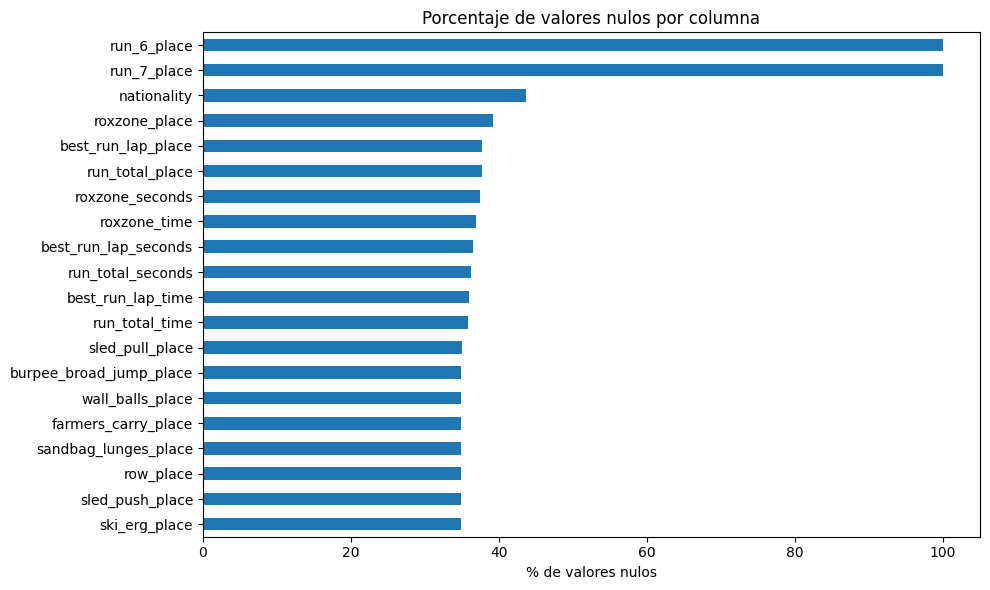

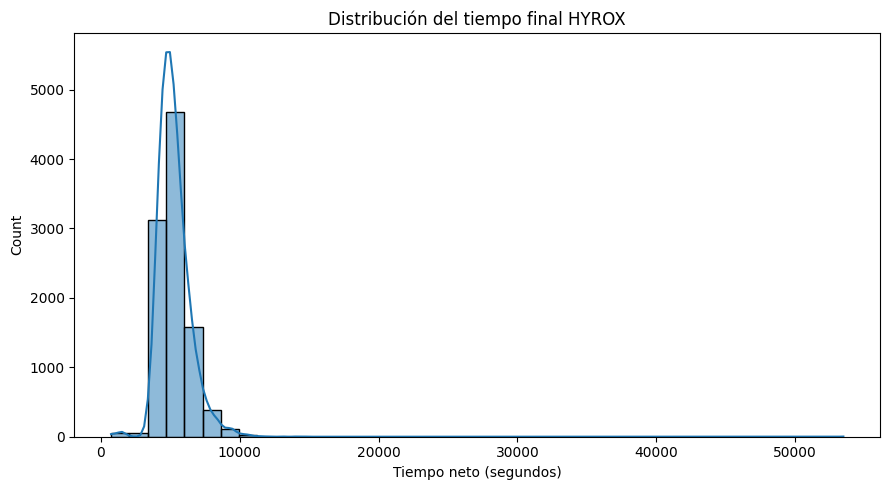

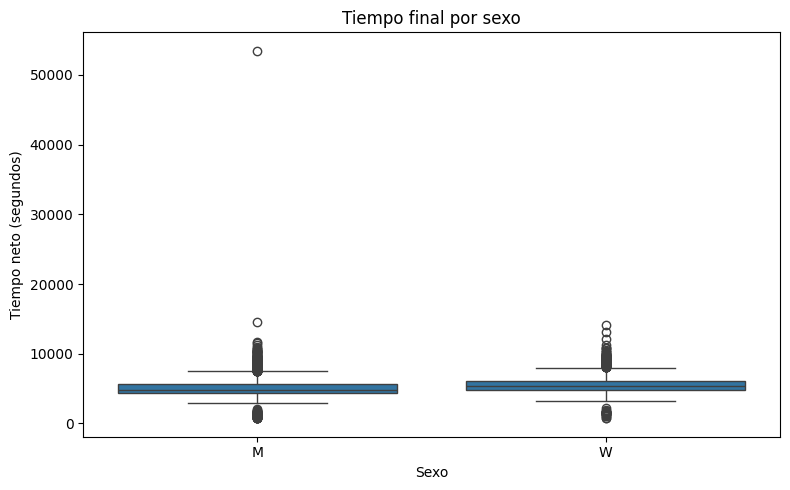

In [8]:
#CELDA 8
import matplotlib.pyplot as plt
import seaborn as sns

GRAFICAS = BASE / "evidencias" / "graficas"
GRAFICAS.mkdir(parents=True, exist_ok=True)

# Gráfica de valores nulos
nulos = (
    muestra.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .head(20)
    .sort_values()
)

plt.figure(figsize=(10, 6))
nulos.plot(kind="barh")
plt.title("Porcentaje de valores nulos por columna")
plt.xlabel("% de valores nulos")
plt.tight_layout()
plt.savefig(GRAFICAS / "valores_nulos.png", dpi=150)
plt.show()

# Distribución del tiempo final
plt.figure(figsize=(9, 5))
sns.histplot(
    data=muestra,
    x="finish_seconds",
    bins=40,
    kde=True
)
plt.title("Distribución del tiempo final HYROX")
plt.xlabel("Tiempo neto (segundos)")
plt.tight_layout()
plt.savefig(GRAFICAS / "distribucion_finish_seconds.png", dpi=150)
plt.show()

# Distribución por sexo, si está disponible
if "sex" in muestra.columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(
        data=muestra,
        x="sex",
        y="finish_seconds"
    )
    plt.title("Tiempo final por sexo")
    plt.xlabel("Sexo")
    plt.ylabel("Tiempo neto (segundos)")
    plt.tight_layout()
    plt.savefig(GRAFICAS / "tiempo_por_sexo.png", dpi=150)
    plt.show()

In [9]:
#CELDA 9
from sklearn.model_selection import GroupShuffleSplit

OBJETIVO = "finish_seconds"

# Contexto que podría conocerse antes de competir
candidatas = [
    "season",
    "year",
    "city",
    "sex",
    "age_group",
    "division",
    "nationality",
]

predictoras = [
    c for c in candidatas
    if c in muestra.columns
]

if not predictoras:
    raise ValueError(
        "No se encontraron predictores de contexto disponibles."
    )

# Para evaluar generalización entre eventos, necesitamos grupos.
if "event_id" in muestra.columns:
    columna_grupo = "event_id"
elif {"season", "year", "city", "division"}.issubset(muestra.columns):
    # Alternativa conservadora si falta event_id
    columna_grupo = None
else:
    columna_grupo = None

if columna_grupo is None:
    raise ValueError(
        "No se encontró un identificador fiable de evento. "
        "Revisa las columnas antes de entrenar para evitar "
        "una evaluación engañosa."
    )

# Conservar filas que tengan identificador de grupo
datos_modelo = muestra.dropna(
    subset=[OBJETIVO, columna_grupo]
).copy()

X = datos_modelo[predictoras].copy()
y = datos_modelo[OBJETIVO].copy()
grupos = datos_modelo[columna_grupo].astype(str)

print("Predictores:", predictoras)
print("Variable objetivo:", OBJETIVO)
print("Agrupación:", columna_grupo)
print("Registros disponibles:", len(datos_modelo))
print("Eventos distintos:", grupos.nunique())

# División por eventos, no por filas
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEMILLA
)

idx_train, idx_test = next(
    splitter.split(X, y, groups=grupos)
)

X_train = X.iloc[idx_train].copy()
X_test = X.iloc[idx_test].copy()
y_train = y.iloc[idx_train].copy()
y_test = y.iloc[idx_test].copy()

grupos_train = grupos.iloc[idx_train]
grupos_test = grupos.iloc[idx_test]

assert set(grupos_train).isdisjoint(set(grupos_test))

print("Entrenamiento:", len(X_train))
print("Prueba:", len(X_test))
print("Eventos en entrenamiento:", grupos_train.nunique())
print("Eventos en prueba:", grupos_test.nunique())

Predictores: ['season', 'year', 'city', 'sex', 'age_group', 'division', 'nationality']
Variable objetivo: finish_seconds
Agrupación: event_id
Registros disponibles: 10000
Eventos distintos: 1664
Entrenamiento: 8053
Prueba: 1947
Eventos en entrenamiento: 1331
Eventos en prueba: 333


In [10]:
#CELDA 10
import numpy as np
import joblib
import mlflow
import mlflow.sklearn

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

numericas = X_train.select_dtypes(include=np.number).columns.tolist()
categoricas = [c for c in X_train.columns if c not in numericas]

transformadores = []

if numericas:
    pipeline_numerico = Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler()),
    ])
    transformadores.append(
        ("numericas", pipeline_numerico, numericas)
    )

if categoricas:
    pipeline_categorico = Pipeline([
        ("imputador", SimpleImputer(strategy="most_frequent")),
        ("codificador", OneHotEncoder(handle_unknown="ignore")),
    ])
    transformadores.append(
        ("categoricas", pipeline_categorico, categoricas)
    )

preprocesador = ColumnTransformer(
    transformers=transformadores,
    remainder="drop"
)

if grupos_train.nunique() < 5:
    raise ValueError(
        "Hay menos de cinco eventos en entrenamiento. "
        "Necesitas una muestra con más eventos distintos."
    )

cv = GroupKFold(n_splits=5)

print("Variables numéricas:", numericas)
print("Variables categóricas:", categoricas)
print("Validación cruzada: 5 particiones agrupadas por evento")

Variables numéricas: []
Variables categóricas: ['season', 'year', 'city', 'sex', 'age_group', 'division', 'nationality']
Validación cruzada: 5 particiones agrupadas por evento


In [11]:

# CELDA 11: Entrenamiento, GridSearchCV y MLflow

from pathlib import Path
import numpy as np
import pandas as pd
import mlflow
import mlflow.sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

# 1. Directorios
BASE_DIR = Path("/content/Actividad5")
EVIDENCIAS_DIR = BASE_DIR / "evidencias"
MODELOS_DIR = BASE_DIR / "modelos"
MLFLOW_DIR = EVIDENCIAS_DIR / "mlflow"
MLFLOW_DIR.mkdir(parents=True, exist_ok=True)

EVIDENCIAS_DIR.mkdir(parents=True, exist_ok=True)
MODELOS_DIR.mkdir(parents=True, exist_ok=True)

# Usar SQLite como backend de seguimiento de MLflow
RUTA_BD_MLFLOW = (MLFLOW_DIR / "mlflow.db").resolve()
URI_MLFLOW = f"sqlite:///{RUTA_BD_MLFLOW}"

mlflow.set_tracking_uri(URI_MLFLOW)
mlflow.set_experiment("Actividad5-HYROX-Regresion")

print("MLflow configurado correctamente.")
print("Base de datos:", RUTA_BD_MLFLOW)

# 3. Identificar tipos de variables
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# 4. Preprocesamiento
transformers = []

if numeric_features:
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    transformers.append(
        ("num", numeric_pipeline, numeric_features)
    )

if categorical_features:
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    transformers.append(
        ("cat", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

# 5. Modelos y espacios de hiperparámetros
modelos = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(
        random_state=42,
        n_jobs=1
    )
}

param_grids = {
    "LinearRegression": {
        "model__fit_intercept": [True, False]
    },
    "RandomForest": {
        "model__n_estimators": [50, 100],
        "model__max_depth": [10, 15],
        "model__min_samples_leaf": [1, 3]
    }
}

# 6. Validación cruzada agrupada por evento
cv = GroupKFold(n_splits=5)

# Reiniciar resultados para evitar duplicados de ejecuciones anteriores
resultados = []
mejor_mae = float("inf")
mejor_modelo = None
mejor_nombre = None

# 7. Entrenar y registrar experimentos
for nombre, estimador in modelos.items():

    print(f"Entrenando: {nombre}", flush=True)

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", estimador)
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[nombre],
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
        return_train_score=True,
        refit=True
    )

    with mlflow.start_run(run_name=nombre):

        # La validación usa grupos de eventos, no filas al azar
        grid_search.fit(
            X_train,
            y_train,
            groups=grupos_train
        )

        modelo_final = grid_search.best_estimator_
        predicciones = modelo_final.predict(X_test)

        mae = mean_absolute_error(y_test, predicciones)
        rmse = np.sqrt(mean_squared_error(y_test, predicciones))
        r2 = r2_score(y_test, predicciones)

        # Parámetros y métricas con nombres consistentes
        mlflow.log_param("modelo", nombre)
        mlflow.log_param("validacion", "GroupKFold_5")
        mlflow.log_params(grid_search.best_params_)

        mlflow.log_metric("MAE_test_segundos", float(mae))
        mlflow.log_metric("RMSE_test_segundos", float(rmse))
        mlflow.log_metric("R2_test", float(r2))
        mlflow.log_metric(
            "MAE_CV_segundos",
            float(-grid_search.best_score_)
        )

        # Registrar modelo entrenado
        import tempfile
        import os
        import joblib
        with tempfile.TemporaryDirectory() as temp_dir:
              ruta_modelo = os.path.join(temp_dir, "modelo_entrenado.joblib")
              joblib.dump(modelo_final, ruta_modelo)

              mlflow.log_artifact(
                  ruta_modelo,
                  artifact_path="modelo_entrenado"
                  )

        resultados.append({
            "modelo": nombre,
            "MAE_test_segundos": mae,
            "RMSE_test_segundos": rmse,
            "R2_test": r2,
            "MAE_CV_segundos": -grid_search.best_score_,
            "mejores_parametros": str(grid_search.best_params_)
        })

        if mae < mejor_mae:
            mejor_mae = mae
            mejor_modelo = modelo_final
            mejor_nombre = nombre

        print("Mejores parámetros:", grid_search.best_params_)
        print(f"MAE prueba: {mae:.2f} segundos")
        print(f"RMSE prueba: {rmse:.2f} segundos")
        print(f"R² prueba: {r2:.4f}")

# 8. Guardar comparación y mejor modelo
resultados_df = pd.DataFrame(resultados).sort_values(
    "MAE_test_segundos"
).reset_index(drop=True)

resultados_df.to_csv(
    EVIDENCIAS_DIR / "comparacion_modelos.csv",
    index=False
)

joblib.dump(
    mejor_modelo,
    MODELOS_DIR / "mejor_modelo_hyrox.joblib"
)

# Guardar predicciones del mejor modelo para análisis posterior
predicciones_finales = mejor_modelo.predict(X_test)

pd.DataFrame({
    "real_segundos": np.asarray(y_test),
    "predicho_segundos": predicciones_finales,
    "error_segundos": np.asarray(y_test) - predicciones_finales
}).to_csv(
    EVIDENCIAS_DIR / "predicciones_test.csv",
    index=False
)

print("\n=== COMPARACIÓN FINAL ===")
display(resultados_df)
print("Mejor modelo:", mejor_nombre)
print(f"MAE del mejor modelo: {mejor_mae:.2f} segundos")
print("Experimentos MLflow:", MLFLOW_DIR)


2026/10/18 20:33:56 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/18 20:33:56 INFO mlflow.store.db.utils: Updating database tables
2026/10/18 20:34:01 INFO mlflow.tracking.fluent: Experiment with name 'Actividad5-HYROX-Regresion' does not exist. Creating a new experiment.


MLflow configurado correctamente.
Base de datos: /content/Actividad5/evidencias/mlflow/mlflow.db
Entrenando: LinearRegression
Mejores parámetros: {'model__fit_intercept': False}
MAE prueba: 752.19 segundos
RMSE prueba: 1001.00 segundos
R² prueba: 0.2132
Entrenando: RandomForest
Mejores parámetros: {'model__max_depth': 15, 'model__min_samples_leaf': 3, 'model__n_estimators': 50}
MAE prueba: 760.92 segundos
RMSE prueba: 1022.78 segundos
R² prueba: 0.1786

=== COMPARACIÓN FINAL ===


,modelo,MAE_test_segundos,RMSE_test_segundos,R2_test,MAE_CV_segundos,mejores_parametros
0,LinearRegression,752.187585,1001.002582,0.213228,765.958632,{'model__fit_intercept': False}
1,RandomForest,760.921424,1022.776135,0.178629,774.732092,"{'model__max_depth': 15, 'model__min_samples_l..."


Mejor modelo: LinearRegression
MAE del mejor modelo: 752.19 segundos
Experimentos MLflow: /content/Actividad5/evidencias/mlflow


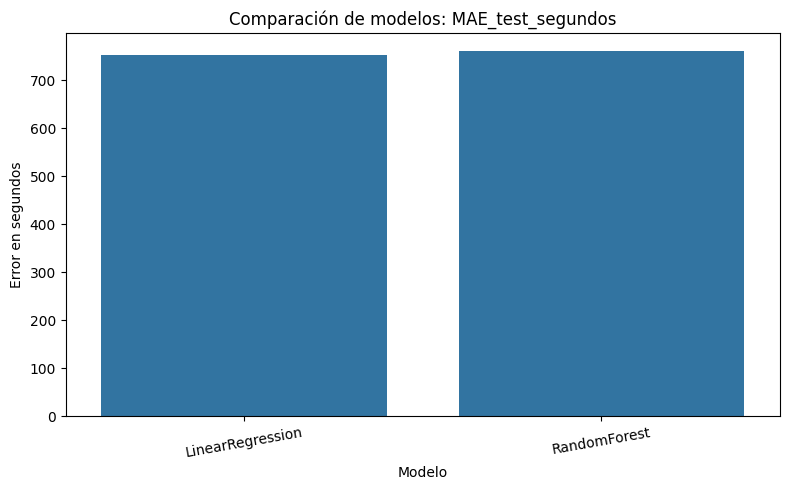

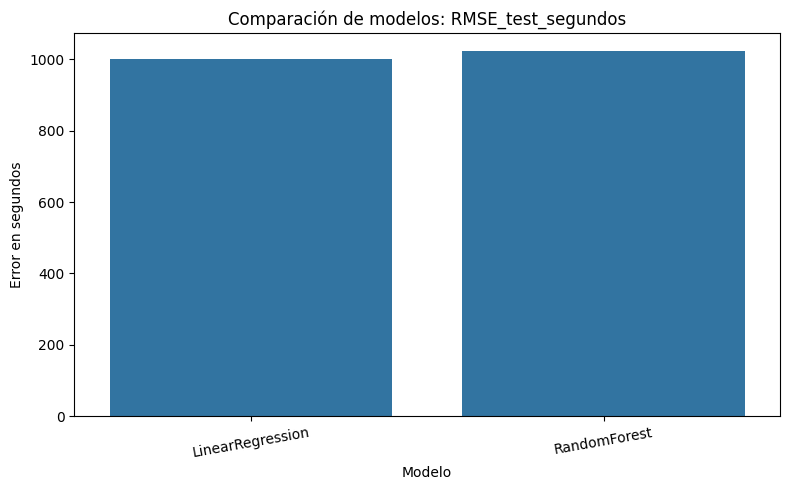

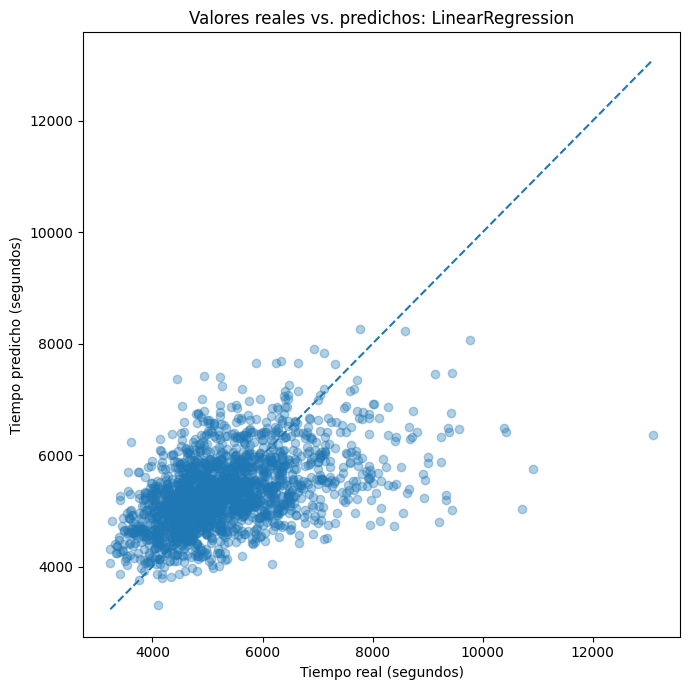

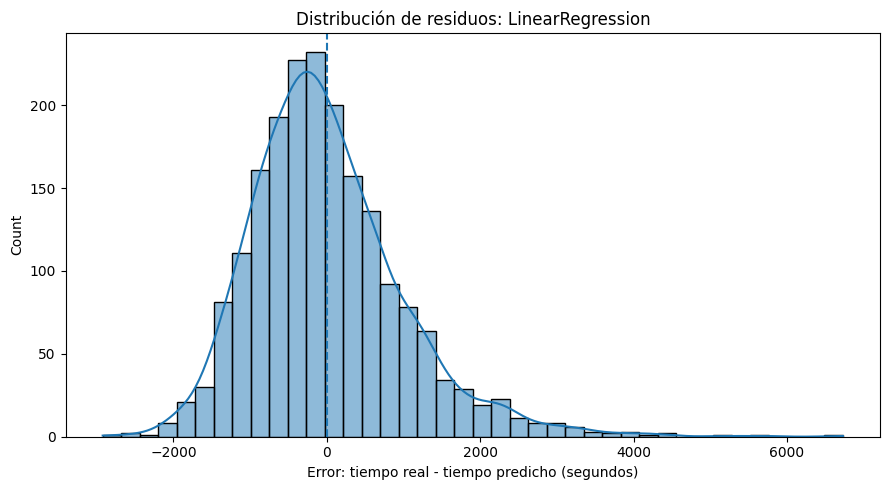

Mejor modelo por MAE: LinearRegression
Gráficas guardadas en: /content/Actividad5/evidencias/graficas


In [12]:
#CELDA 12
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import mlflow

# Recuperar resultados_df desde los archivos generados o variables globales
if "resultados_df" not in globals():
    ruta_csv = BASE / "evidencias" / "comparacion_modelos.csv"
    if ruta_csv.exists():
        resultados_df = pd.read_csv(ruta_csv)
    else:
        raise NameError(
            "La variable 'resultados_df' no está definida y tampoco se encontró el archivo backup en '" + str(ruta_csv) + "'. "
            "Por favor, ejecuta primero la celda de entrenamiento de los modelos."
        )

# Cargar el mejor modelo guardado en la carpeta de modelos
mejor_modelo_path = BASE / "modelos" / "mejor_modelo_hyrox.joblib"
if mejor_modelo_path.exists():
    mejor_modelo = joblib.load(mejor_modelo_path)
else:
    mejor_modelo = globals().get("mejor_modelo", None)

# Comparación de errores (usando los nombres de columna reales)
metricas = ["MAE_test_segundos", "RMSE_test_segundos"]

for metrica in metricas:
    plt.figure(figsize=(8, 5))
    sns.barplot(
        data=resultados_df,
        x="modelo",
        y=metrica
    )
    plt.title(f"Comparación de modelos: {metrica}")
    plt.xlabel("Modelo")
    plt.ylabel("Error en segundos")
    plt.xticks(rotation=10)
    plt.tight_layout()
    plt.savefig(GRAFICAS / f"comparacion_{metrica}.png", dpi=150)
    plt.show()

# Predicciones del mejor modelo según MAE de prueba
mejor_nombre = resultados_df.sort_values(
    "MAE_test_segundos"
).iloc[0]["modelo"]

if mejor_modelo is not None:
    predicciones = mejor_modelo.predict(X_test)

    plt.figure(figsize=(7, 7))
    plt.scatter(y_test, predicciones, alpha=0.35)

    limite_min = min(y_test.min(), predicciones.min())
    limite_max = max(y_test.max(), predicciones.max())

    plt.plot(
        [limite_min, limite_max],
        [limite_min, limite_max],
        linestyle="--"
    )

    plt.title(f"Valores reales vs. predichos: {mejor_nombre}")
    plt.xlabel("Tiempo real (segundos)")
    plt.ylabel("Tiempo predicho (segundos)")
    plt.tight_layout()
    plt.savefig(GRAFICAS / "real_vs_predicho.png", dpi=150)
    plt.show()

    # Residuos
    residuos = y_test.to_numpy() - predicciones

    plt.figure(figsize=(9, 5))
    sns.histplot(residuos, bins=40, kde=True)
    plt.axvline(0, linestyle="--")
    plt.title(f"Distribución de residuos: {mejor_nombre}")
    plt.xlabel("Error: tiempo real - tiempo predicho (segundos)")
    plt.tight_layout()
    plt.savefig(GRAFICAS / "distribucion_residuos.png", dpi=150)
    plt.show()

    print("Mejor modelo por MAE:", mejor_nombre)
    print("Gráficas guardadas en:", GRAFICAS)
else:
    print(f"No se pudo cargar el modelo '{mejor_nombre}' para generar los diagramas de dispersión y residuos.")

In [13]:

# CELDA 13: Consultar experimentos de MLflow

from pathlib import Path
import pandas as pd
import mlflow
from mlflow.tracking import MlflowClient

BASE_DIR = Path("/content/Actividad5")
MLFLOW_DIR = BASE_DIR / "evidencias" / "mlflow"
RUTA_BD_MLFLOW = (MLFLOW_DIR / "mlflow.db").resolve()

# Usar la misma base de datos SQLite que la celda 11
mlflow.set_tracking_uri(f"sqlite:///{RUTA_BD_MLFLOW}")

cliente = MlflowClient()

experimento = cliente.get_experiment_by_name(
    "Actividad5-HYROX-Regresion"
)

if experimento is None:
    raise ValueError(
        "No se encontró el experimento. "
        "Ejecuta primero la celda 11 y verifica que haya terminado."
    )

corridas = cliente.search_runs(
    experiment_ids=[experimento.experiment_id],
    order_by=["start_time DESC"],
    max_results=50
)

filas = []

for corrida in corridas:
    filas.append({
        "run_id": corrida.info.run_id,
        "estado": corrida.info.status,
        "modelo": corrida.data.params.get("modelo", "No especificado"),
        "MAE_test_segundos": corrida.data.metrics.get(
            "MAE_test_segundos"
        ),
        "RMSE_test_segundos": corrida.data.metrics.get(
            "RMSE_test_segundos"
        ),
        "R2_test": corrida.data.metrics.get("R2_test"),
        "MAE_CV_segundos": corrida.data.metrics.get(
            "MAE_CV_segundos"
        )
    })

df_mlflow = pd.DataFrame(filas)

if not df_mlflow.empty:
    display(df_mlflow)

    ruta_resumen = (
        BASE_DIR / "evidencias" / "mlflow" / "resumen_mlflow.csv"
    )
    ruta_resumen.parent.mkdir(parents=True, exist_ok=True)

    df_mlflow.to_csv(ruta_resumen, index=False)

    print("\nEstados de las ejecuciones:")
    print(df_mlflow["estado"].value_counts(dropna=False))
    print("Resumen guardado en:", ruta_resumen)
else:
    print("No hay ejecuciones registradas en este experimento.")

print("Base de datos MLflow:", RUTA_BD_MLFLOW)


,run_id,estado,modelo,MAE_test_segundos,RMSE_test_segundos,R2_test,MAE_CV_segundos
0,bb44729946144650b756ff1fe358eb5c,FINISHED,RandomForest,760.921424,1022.776135,0.178629,774.732092
1,6ac07140e38f47288fdfc9c9a8b428be,FINISHED,LinearRegression,752.187585,1001.002582,0.213228,765.958632



Estados de las ejecuciones:
estado
FINISHED    2
Name: count, dtype: int64
Resumen guardado en: /content/Actividad5/evidencias/mlflow/resumen_mlflow.csv
Base de datos MLflow: /content/Actividad5/evidencias/mlflow/mlflow.db


In [14]:
# CELDA 14
requirements = """kagglehub
pandas
numpy
scikit-learn
matplotlib
seaborn
mlflow
joblib
pyarrow
"""

readme = """# Actividad 5: Predicción de tiempos HYROX

## Objetivo
Evaluar modelos de regresión para estimar el tiempo neto de finalización
de una competición HYROX utilizando variables de contexto.

## Modelos
- Regresión lineal
- Random Forest Regressor

## Métricas
- MAE
- RMSE
- R²

## Validación
Separación de entrenamiento y prueba por evento y validación cruzada
GroupKFold de cinco particiones.

## Estructura
- datos/datos_ini: datos originales, sujetos a licencia.
- datos/datos_limp: datos limpios, muestra y diccionario.
- fuentes: scripts y notebook.
- evidencias/mlflow: experimentos y modelos.
- evidencias/graficas: visualizaciones.
- reportes: informe técnico.

## Reproducibilidad
Semilla aleatoria: 42.

Los resultados deben interpretarse considerando que el modelo usa
variables de contexto y no tiempos parciales ni posiciones finales.
"""

changelog = """# CHANGELOG

## 1.0.0
- Creación de la estructura del proyecto.
- Descarga e inspección del dataset.
- Limpieza conservadora y diccionario de datos.
- Generación de una muestra reproducible.
- Entrenamiento y comparación de modelos.
- Seguimiento de experimentos con MLflow.
- Generación de gráficas y resultados.
"""

gitignore = """# Datos grandes y potencialmente sujetos a licencia
datos/datos_ini/*
datos/datos_limp/*.parquet

# Secretos
kaggle.json
.env
*.key

# Python
__pycache__/
*.py[cod]
.venv/

# Notebook
.ipynb_checkpoints/

# MLflow local
evidencias/mlflow/tracking/

# Archivos temporales
.DS_Store
"""

(BASE / "requirements.txt").write_text(
    requirements, encoding="utf-8"
)
(BASE / "README.md").write_text(
    readme, encoding="utf-8"
)
(BASE / "CHANGELOG.md").write_text(
    changelog, encoding="utf-8"
)
(BASE / ".gitignore").write_text(
    gitignore, encoding="utf-8"
)

print("README.md, CHANGELOG.md, requirements.txt y .gitignore creados.")

README.md, CHANGELOG.md, requirements.txt y .gitignore creados.


In [15]:
#CELDA 15
print("Archivos generados:")

for ruta in sorted(BASE.rglob("*")):
    if ruta.is_file():
        print(
            f"{ruta.relative_to(BASE)} "
            f"({ruta.stat().st_size / 1024:.1f} KB)"
        )

print("\nModelos:")
display(resultados_df)

print("\nVerifica manualmente que el notebook esté guardado en:")
print(BASE / "fuentes" / "entrena.ipynb")

Archivos generados:
.gitignore (0.3 KB)
CHANGELOG.md (0.3 KB)
README.md (0.8 KB)
datos/datos_ini/DATA_DICTIONARY.md (4.0 KB)
datos/datos_ini/dataset/dataset/DATA_DICTIONARY.md (4.0 KB)
datos/datos_ini/dataset/dataset/by_event/s1_2018_Essen_HD_999999212F07B5000000003D_M.csv (110.6 KB)
datos/datos_ini/dataset/dataset/by_event/s1_2018_Essen_HD_999999212F07B5000000003D_W.csv (102.7 KB)
datos/datos_ini/dataset/dataset/by_event/s1_2018_Essen_HPRO_999999212F07B5000000003D_M.csv (100.8 KB)
datos/datos_ini/dataset/dataset/by_event/s1_2018_Essen_HPRO_999999212F07B5000000003D_W.csv (26.8 KB)
datos/datos_ini/dataset/dataset/by_event/s1_2018_Essen_H_999999212F07B5000000003D_M.csv (396.0 KB)
datos/datos_ini/dataset/dataset/by_event/s1_2018_Essen_H_999999212F07B5000000003D_W.csv (192.3 KB)
datos/datos_ini/dataset/dataset/by_event/s1_2018_Hamburg_BT1_999999212F07B500000000B5_M.csv (266.5 KB)
datos/datos_ini/dataset/dataset/by_event/s1_2018_Hamburg_BT2_999999212F07B500000000B5_M.csv (249.7 KB)
datos/da

,modelo,MAE_test_segundos,RMSE_test_segundos,R2_test,MAE_CV_segundos,mejores_parametros
0,LinearRegression,752.187585,1001.002582,0.213228,765.958632,{'model__fit_intercept': False}
1,RandomForest,760.921424,1022.776135,0.178629,774.732092,"{'model__max_depth': 15, 'model__min_samples_l..."



Verifica manualmente que el notebook esté guardado en:
/content/Actividad5/fuentes/entrena.ipynb


In [16]:
#CELDA 16
# Evaluación de los modelos entrenados

display(resultados_df)

for _, fila in resultados_df.iterrows():
    print(f"\nModelo: {fila['modelo']}")
    print(f"MAE:  {fila['MAE_test_segundos']:.2f} segundos")
    print(f"RMSE: {fila['RMSE_test_segundos']:.2f} segundos")
    print(f"R²:   {fila['R2_test']:.4f}")

    print(
        f"MAE en minutos: "
        f"{fila['MAE_test_segundos'] / 60:.2f}"
    )


,modelo,MAE_test_segundos,RMSE_test_segundos,R2_test,MAE_CV_segundos,mejores_parametros
0,LinearRegression,752.187585,1001.002582,0.213228,765.958632,{'model__fit_intercept': False}
1,RandomForest,760.921424,1022.776135,0.178629,774.732092,"{'model__max_depth': 15, 'model__min_samples_l..."



Modelo: LinearRegression
MAE:  752.19 segundos
RMSE: 1001.00 segundos
R²:   0.2132
MAE en minutos: 12.54

Modelo: RandomForest
MAE:  760.92 segundos
RMSE: 1022.78 segundos
R²:   0.1786
MAE en minutos: 12.68


In [26]:

from pathlib import Path

BASE = Path("/content/Actividad5")

archivos = [
    "fuentes/entrena.ipynb",
    "README.md",
    "CHANGELOG.md",
    "requirements.txt",
    ".gitignore",
    "datos/datos_limp/hyrox_muestra_10000.parquet",
    "evidencias/mlflow/mlflow.db",
    "evidencias/mlflow/resumen_mlflow.csv",
]

for archivo in archivos:
    ruta = BASE / archivo
    estado = "OK" if ruta.exists() else "FALTA"
    print(f"{estado:6} | {archivo}")

print("\nGráficas guardadas:")
for ruta in sorted((BASE / "evidencias/graficas").glob("*")):
    if ruta.is_file():
        print("OK     |", ruta.name)


FALTA  | fuentes/entrena.ipynb
OK     | README.md
OK     | CHANGELOG.md
OK     | requirements.txt
OK     | .gitignore
OK     | datos/datos_limp/hyrox_muestra_10000.parquet
OK     | evidencias/mlflow/mlflow.db
OK     | evidencias/mlflow/resumen_mlflow.csv

Gráficas guardadas:
OK     | comparacion_MAE_test_segundos.png
OK     | comparacion_RMSE_test_segundos.png
OK     | distribucion_finish_seconds.png
OK     | distribucion_residuos.png
OK     | real_vs_predicho.png
OK     | tiempo_por_sexo.png
OK     | valores_nulos.png
